# Fruits-360 과일 4종 분류 응용예제

수업에서 사용한 사과·파인애플·바나나를 제외하고 **Kiwi, Mango, Orange, Strawberry** 4종을 선정하였다.

진행 순서: 데이터 다운로드 → 이미지 전처리 및 NPY 저장 → K-평균 군집화 → PCA → 로지스틱 회귀 → 결과 비교

> Google Colab에서 **런타임 → 모두 실행**을 누르면 된다. 최초 실행 시 Kaggle 데이터 다운로드 때문에 시간이 걸릴 수 있다.


In [1]:
!pip -q install pillow seaborn


In [2]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from PIL import Image

from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (8, 5)
print('라이브러리 준비 완료')


라이브러리 준비 완료


## 1. Fruits-360 데이터 다운로드 및 과일 4종 선택

Kaggle의 `ruchirtarawat/fruits-dataset-360` 데이터셋을 내려받는다. 폴더명이 조금 달라도 자동으로 과일 폴더를 찾도록 작성했다.


In [3]:
import subprocess
from pathlib import Path

repo = Path('fruits360')
classes_on_disk = ['Kiwi 1', 'Mango 1', 'Orange 1', 'Strawberry 1']
SELECTED = ['Kiwi', 'Mango', 'Orange', 'Strawberry']
IMAGE_SIZE = (100, 100)
MAX_PER_CLASS = 250

if not repo.exists():
    subprocess.run([
        'git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse',
        'https://github.com/fruits-360/fruits-360-100x100.git', str(repo)
    ], check=True)

paths = [f'Training/{name}' for name in classes_on_disk]
subprocess.run(['git', '-C', str(repo), 'sparse-checkout', 'set', *paths], check=True)

class_dirs = {display: repo / 'Training' / disk
              for display, disk in zip(SELECTED, classes_on_disk)}
for name, folder in class_dirs.items():
    count = len(list(folder.glob('*.jpg')))
    print(f'{name:10s}: {folder} ({count}장)')

image_exts = {'.jpg', '.jpeg', '.png', '.bmp'}


Kiwi      : fruits360/Training/Kiwi 1 (466장)
Mango     : fruits360/Training/Mango 1 (490장)
Orange    : fruits360/Training/Orange 1 (479장)
Strawberry: fruits360/Training/Strawberry 1 (492장)


## 2. 이미지 전처리 및 NPY 변환

모든 이미지를 100×100 RGB로 맞춘 뒤 픽셀 값을 배열로 저장한다. 모델 입력은 계산량을 줄이기 위해 회색조로 변환하고 0~1 범위로 정규화한다.


In [4]:
images_rgb, images_gray, labels = [], [], []

for label, class_name in enumerate(SELECTED):
    files = sorted([p for p in class_dirs[class_name].iterdir()
                    if p.is_file() and p.suffix.lower() in image_exts])[:MAX_PER_CLASS]
    for file in files:
        try:
            rgb = Image.open(file).convert('RGB').resize(IMAGE_SIZE)
            rgb_arr = np.asarray(rgb, dtype=np.uint8)
            gray_arr = np.asarray(rgb.convert('L'), dtype=np.float32) / 255.0
            images_rgb.append(rgb_arr)
            images_gray.append(gray_arr)
            labels.append(label)
        except Exception as e:
            print('읽기 실패:', file.name, e)

fruits_rgb = np.stack(images_rgb)
fruits_gray = np.stack(images_gray)
fruits_labels = np.asarray(labels, dtype=np.int64)
class_names = np.asarray(SELECTED)

np.save('fruits4_images.npy', fruits_rgb)
np.save('fruits4_gray.npy', fruits_gray)
np.save('fruits4_labels.npy', fruits_labels)
np.save('fruits4_class_names.npy', class_names)

print('RGB 이미지:', fruits_rgb.shape, fruits_rgb.dtype)
print('회색조 이미지:', fruits_gray.shape, fruits_gray.dtype)
print('레이블:', fruits_labels.shape)
print('클래스별 개수:', dict(zip(*np.unique(fruits_labels, return_counts=True))))
print('NPY 파일 4개 저장 완료')


RGB 이미지: (1000, 100, 100, 3) uint8
회색조 이미지: (1000, 100, 100) float32
레이블: (1000,)
클래스별 개수: {np.int64(0): np.int64(250), np.int64(1): np.int64(250), np.int64(2): np.int64(250), np.int64(3): np.int64(250)}
NPY 파일 4개 저장 완료


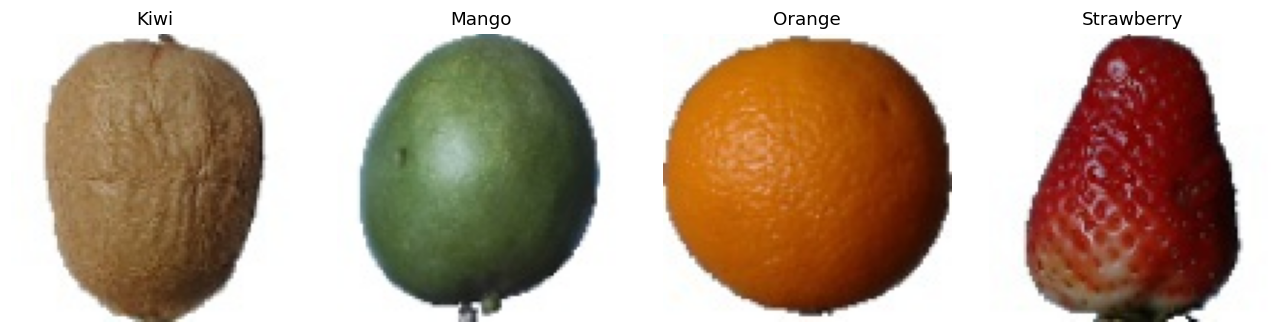

In [5]:
# 클래스별 예시 이미지 출력
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, (ax, name) in enumerate(zip(axes, SELECTED)):
    idx = np.where(fruits_labels == i)[0][0]
    ax.imshow(fruits_rgb[idx])
    ax.set_title(name)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 3. K-평균(K-Means) 군집화

레이블을 사용하지 않고 이미지의 색상 통계(RGB 평균·표준편차)로 4개 군집을 만든다. K-평균 군집 번호는 실제 클래스 번호와 의미가 다르므로 Hungarian matching으로 가장 잘 대응시켜 정확도를 계산한다.


K-평균 대응 정확도: 1.0000
실루엣 점수: 0.8255


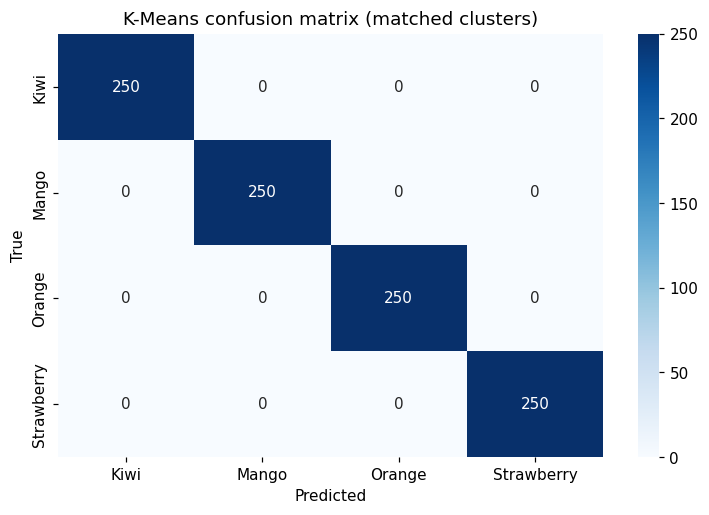

In [6]:
# 각 이미지에서 RGB 채널별 평균과 표준편차를 뽑아 6개 특성 생성
rgb_float = fruits_rgb.astype(np.float32) / 255.0
color_mean = rgb_float.mean(axis=(1, 2))
color_std = rgb_float.std(axis=(1, 2))
cluster_features = np.column_stack([color_mean, color_std])

cluster_scaled = StandardScaler().fit_transform(cluster_features)
kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=20)
cluster_id = kmeans.fit_predict(cluster_scaled)

cm_raw = confusion_matrix(fruits_labels, cluster_id)
row_ind, col_ind = linear_sum_assignment(-cm_raw)
cluster_to_class = {cluster: true_class for true_class, cluster in zip(row_ind, col_ind)}
cluster_pred = np.array([cluster_to_class[c] for c in cluster_id])

kmeans_acc = accuracy_score(fruits_labels, cluster_pred)
silhouette = silhouette_score(cluster_scaled, cluster_id)
print(f'K-평균 대응 정확도: {kmeans_acc:.4f}')
print(f'실루엣 점수: {silhouette:.4f}')

cm_kmeans = confusion_matrix(fruits_labels, cluster_pred)
sns.heatmap(cm_kmeans, annot=True, fmt='d', cmap='Blues',
            xticklabels=SELECTED, yticklabels=SELECTED)
plt.title('K-Means confusion matrix (matched clusters)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


## 4. 주성분 분석(PCA)

100×100 회색조 이미지는 10,000개 특성을 가진다. 계산 시간을 고려해 주요 정보를 담은 100개 주성분으로 축소한다.


PCA 전 특성 수: 10000
PCA 후 주성분 수: 100
100개 주성분 누적 설명 분산: 0.9760964


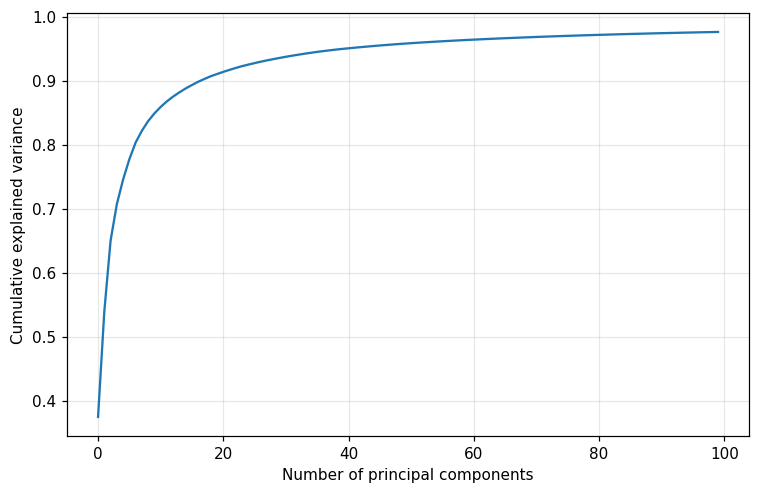

In [7]:
X = fruits_gray.reshape(len(fruits_gray), -1)
y = fruits_labels

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

pca = PCA(n_components=100, svd_solver='randomized', random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print('PCA 전 특성 수:', X_train.shape[1])
print('PCA 후 주성분 수:', pca.n_components_)
print('100개 주성분 누적 설명 분산:', pca.explained_variance_ratio_.sum())

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.grid(alpha=0.3)
plt.show()


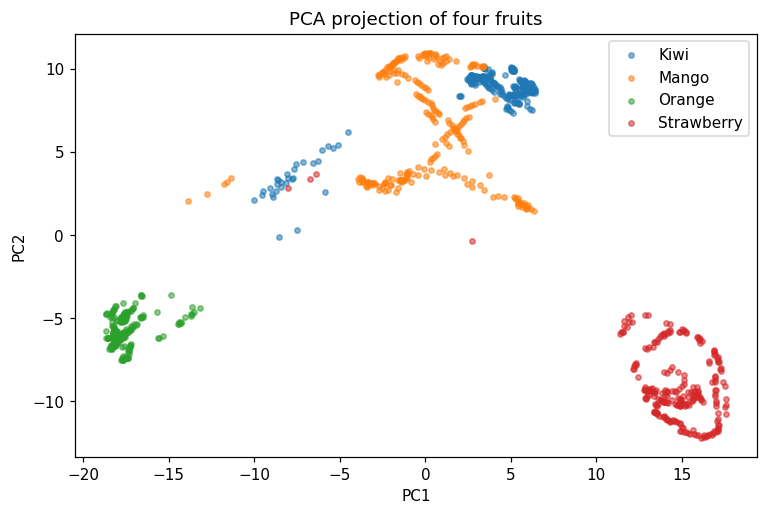

In [8]:
# 첫 두 주성분으로 데이터 분포 시각화
X_2d = PCA(n_components=2, random_state=SEED).fit_transform(X)
for i, name in enumerate(SELECTED):
    mask = y == i
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=12, alpha=0.55, label=name)
plt.title('PCA projection of four fruits')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()


## 5. PCA + 로지스틱 회귀 분류

훈련 데이터에만 표준화와 PCA를 학습하여 데이터 누수를 막고, 다중 클래스 로지스틱 회귀로 과일 종류를 예측한다.


훈련 정확도: 1.0000
테스트 정확도: 1.0000

분류 보고서
              precision    recall  f1-score   support

        Kiwi       1.00      1.00      1.00        50
       Mango       1.00      1.00      1.00        50
      Orange       1.00      1.00      1.00        50
  Strawberry       1.00      1.00      1.00        50

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



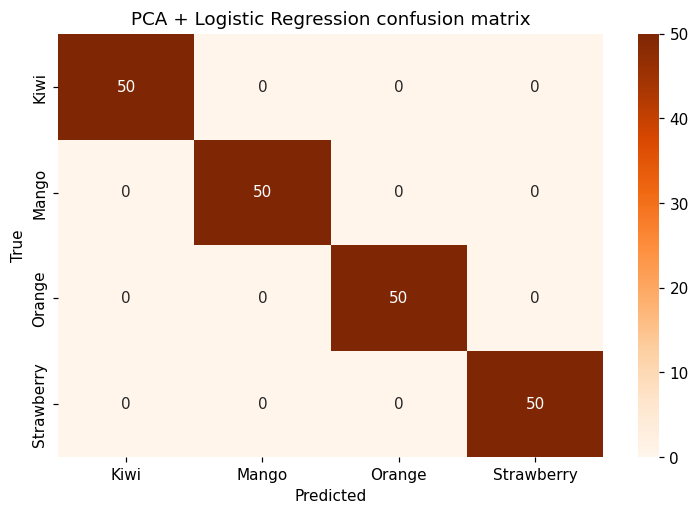

In [9]:
model = make_pipeline(
    StandardScaler(),
    PCA(n_components=100, svd_solver='randomized', random_state=SEED),
    LogisticRegression(max_iter=3000, random_state=SEED)
)
model.fit(X_train, y_train)

train_acc = model.score(X_train, y_train)
test_acc = model.score(X_test, y_test)
y_pred = model.predict(X_test)

print(f'훈련 정확도: {train_acc:.4f}')
print(f'테스트 정확도: {test_acc:.4f}')
print('\n분류 보고서')
print(classification_report(y_test, y_pred, target_names=SELECTED))

cm_lr = confusion_matrix(y_test, y_pred)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges',
            xticklabels=SELECTED, yticklabels=SELECTED)
plt.title('PCA + Logistic Regression confusion matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


## 6. 결과 비교 및 결론

- K-평균은 정답 레이블 없이 비슷한 색상 분포끼리 묶는 비지도학습이므로, 색이 비슷한 과일 사이에서 혼동이 생길 수 있다.
- PCA는 10,000개의 픽셀 특성을 훨씬 적은 주성분으로 축소하여 계산량과 중복 정보를 줄인다.
- 로지스틱 회귀는 정답 레이블을 사용해 클래스 경계를 학습하므로 K-평균보다 분류 정확도가 일반적으로 높다.


In [10]:
print('===== 최종 결과 =====')
print(f'선정 과일: {SELECTED}')
print(f'전체 이미지 수: {len(y)}')
print(f'K-평균 대응 정확도: {kmeans_acc:.4f}')
print(f'K-평균 실루엣 점수: {silhouette:.4f}')
print(f'로지스틱 회귀 훈련 정확도: {train_acc:.4f}')
print(f'로지스틱 회귀 테스트 정확도: {test_acc:.4f}')


===== 최종 결과 =====
선정 과일: ['Kiwi', 'Mango', 'Orange', 'Strawberry']
전체 이미지 수: 1000
K-평균 대응 정확도: 1.0000
K-평균 실루엣 점수: 0.8255
로지스틱 회귀 훈련 정확도: 1.0000
로지스틱 회귀 테스트 정확도: 1.0000


### 제출 파일

이 노트북을 실행하면 작업 폴더에 다음 NPY 파일이 생성된다.

- `fruits4_images.npy`: RGB 이미지
- `fruits4_gray.npy`: 모델용 회색조 이미지
- `fruits4_labels.npy`: 정답 레이블
- `fruits4_class_names.npy`: 클래스 이름

데이터 출처: [Fruits dataset 360 (Kaggle)](https://www.kaggle.com/datasets/ruchirtarawat/fruits-dataset-360)
